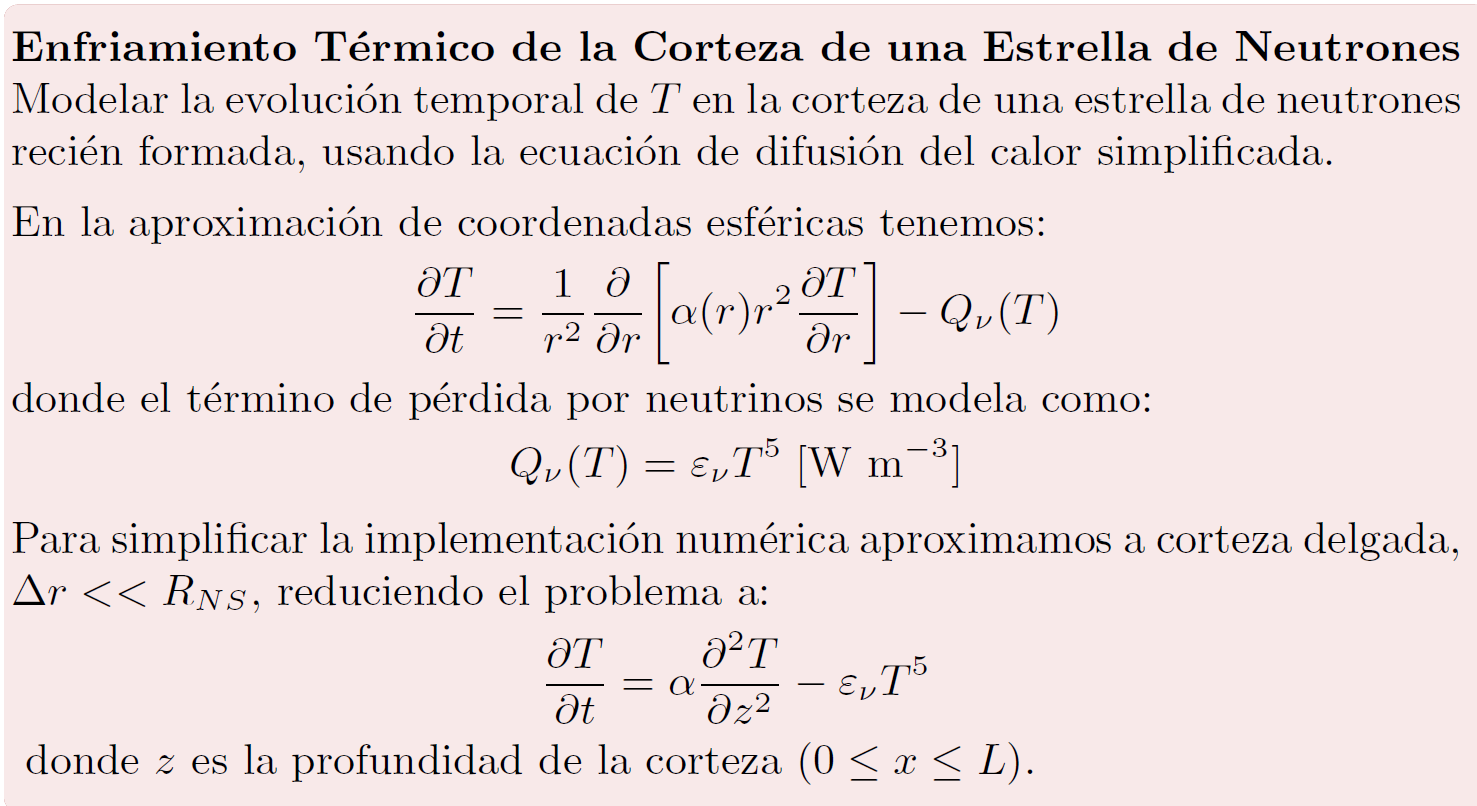

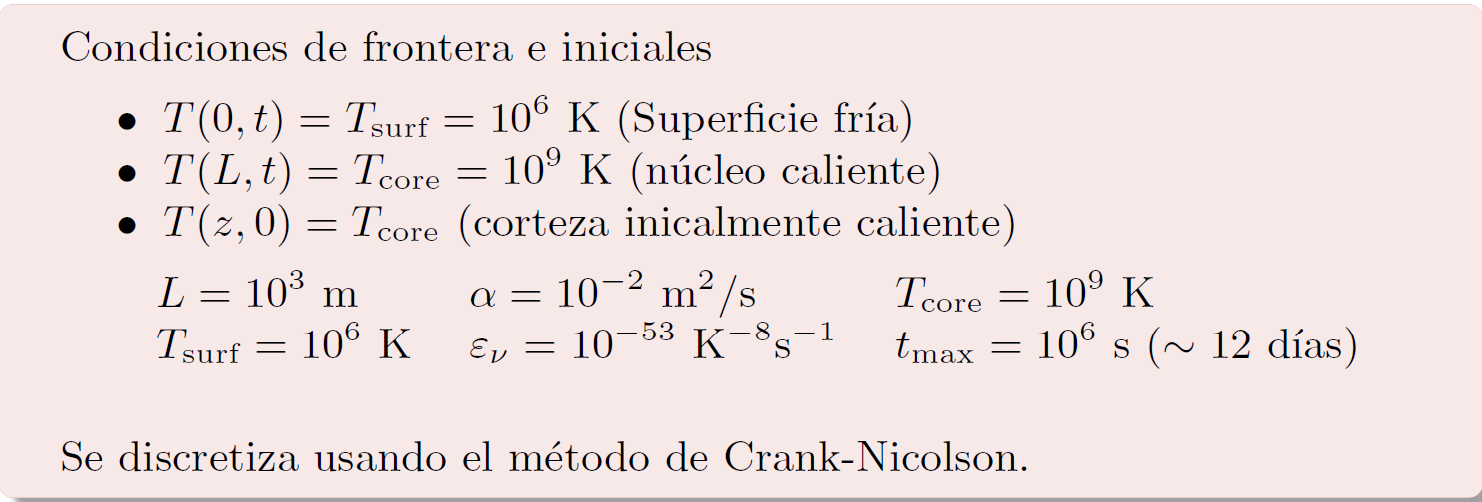

## Módulo 1: parámetros y malla

In [ ]:
# parámetros físicos
L = 1.0e3
alpha = 1.0e-2
eps_nu = 1.0e-53
p_nu = 5
T_core = 1.0e9
T_surf = 1.0e6
t_max = 1.0e6

# parámetros numéricos
N = 100
dx = L / (N - 1)
dt = 1000.0
lam = alpha * dt / dx**2
n_steps = int(round(t_max / dt))

print("dx =", dx, "m")
print("lambda =", lam)
print("n_steps =", n_steps)

# verificar estabilidad
if lam > 10.0:
    print("lambda muy grande, considerar reducir dt")

# inicializar malla
x = np.linspace(0, L, N)
T = np.full(N, T_core)
T[0] = T_surf
T[N - 1] = T_core

dx = 10.1010101010101 m
lambda = 0.09801000000000001
n_steps = 1000


## Módulos 2, 3 y 4: ensamblado, eliminación gaussiana e integración temporal

In [24]:
n = N - 2
tiempos_salida = [1.0e3, 1.0e4, 1.0e5, 1.0e6]
T_history = []
t_history = []
t_lista = []
F_lista = []
t = 0.0

for paso in range(1, n_steps + 1):

    diag_inf = np.full(n, -lam / 2.0)
    diag_pri = np.full(n, 1.0 + lam)
    diag_sup = np.full(n, -lam / 2.0)

    b = np.zeros(n)
    for i in range(1, N - 1):
        Q_nu_i = eps_nu * T[i]**p_nu
        b[i - 1] = (lam / 2.0) * T[i - 1] + (1.0 - lam) * T[i] + (lam / 2.0) * T[i + 1] - dt * Q_nu_i

    b[0] = b[0] + (lam / 2.0) * T[0]
    b[n - 1] = b[n - 1] + (lam / 2.0) * T[N - 1]

    # matriz A
    A = np.zeros((n, n))
    for k in range(n):
        A[k, k] = diag_pri[k]
        if k > 0:
            A[k, k - 1] = diag_inf[k]
        if k < n - 1:
            A[k, k + 1] = diag_sup[k]

    A0 = A.copy()
    b0 = b.copy()

    # eliminación hacia adelante con pivoteo parcial
    for k in range(n - 1):
        fila_piv = k + np.argmax(np.abs(A[k:, k]))
        if fila_piv != k:
            fila_tmp = A[k, :].copy()
            A[k, :] = A[fila_piv, :]
            A[fila_piv, :] = fila_tmp
            b_tmp = b[k]
            b[k] = b[fila_piv]
            b[fila_piv] = b_tmp
        factores = A[k + 1:, k] / A[k, k]
        A[k + 1:, k:] = A[k + 1:, k:] - np.outer(factores, A[k, k:])
        b[k + 1:] = b[k + 1:] - factores * b[k]

    # sustitución hacia atrás
    T_interior = np.zeros(n)
    T_interior[n - 1] = b[n - 1] / A[n - 1, n - 1]
    for i in range(n - 2, -1, -1):
        T_interior[i] = (b[i] - np.dot(A[i, i + 1:], T_interior[i + 1:])) / A[i, i]

    if paso == 1:
        residuo = np.max(np.abs(A0 @ T_interior - b0))
        print("residuo máximo del paso 1:", residuo)

    # actualizar temperatura
    T[1:N - 1] = T_interior
    T[0] = T_surf
    T[N - 1] = T_core
    t = t + dt

    # flujo de calor en la superficie
    F_surf = -alpha * (T[1] - T[0]) / dx
    t_lista.append(t)
    F_lista.append(F_surf)

    # guardar
    if t in tiempos_salida:
        T_history.append(T.copy())
        t_history.append(t)

residuo máximo del paso 1: 2.384185791015625e-07


## Tarea 1: perfiles de temperatura

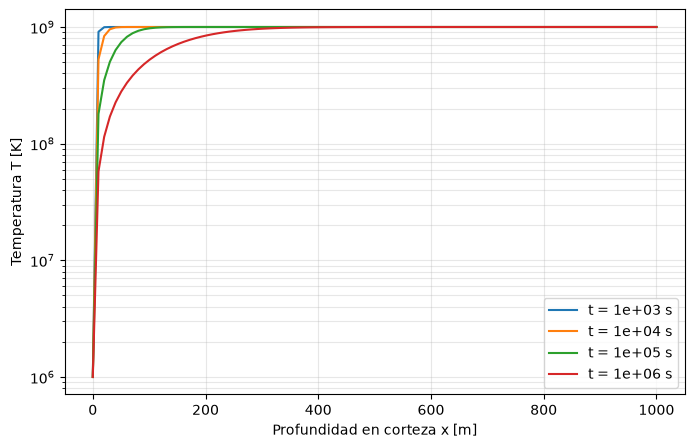

In [16]:
plt.figure(figsize=(8, 5))
for k in range(len(T_history)):
    plt.plot(x, T_history[k], label=f"t = {t_history[k]:.0e} s")
plt.xlabel("Profundidad en corteza x [m]")
plt.ylabel("Temperatura T [K]")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

## Tarea 2: flujo de calor superficial

pendiente para t >= 1e5 s: -0.14240413892038425


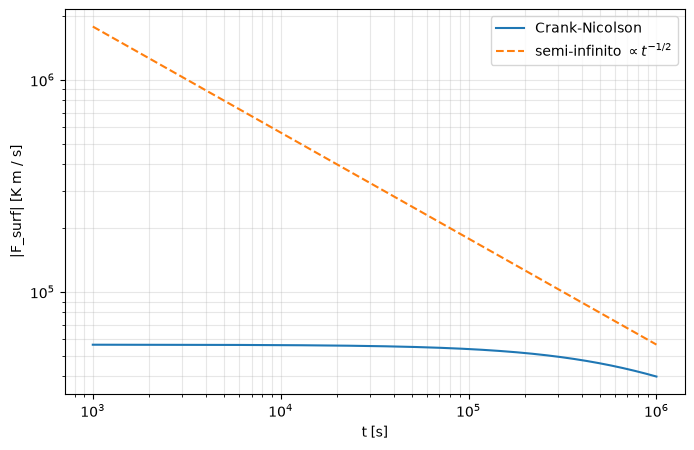

In [21]:
t_arr = np.array(t_lista)
F_arr = np.abs(np.array(F_lista))
F_teo = (T_core - T_surf) * np.sqrt(alpha / (np.pi * t_arr))

mascara = t_arr >= 1.0e5
pendiente, intercepto = np.polyfit(np.log10(t_arr[mascara]), np.log10(F_arr[mascara]), 1)
print("pendiente para t >= 1e5 s:", pendiente)

plt.figure(figsize=(8, 5))
plt.loglog(t_arr, F_arr, label="Crank-Nicolson")
plt.loglog(t_arr, F_teo, "--", label="semi-infinito $\\propto t^{-1/2}$")
plt.xlabel("t [s]")
plt.ylabel("|F_surf| [K m / s]")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

## Tarea 3: comparación de métodos

In [22]:
dts = [1.0e3, 1.0e4]
metodos = ["Explícito", "Implícito", "Crank-Nicolson"]
thetas = [0.0, 1.0, 0.5]
resultados = {}

for dt_c in dts:
    lam_c = alpha * dt_c / dx**2
    n_c = int(round(t_max / dt_c))

    for m in range(3):
        theta = thetas[m]
        T_c = np.full(N, T_core)
        T_c[0] = T_surf
        T_c[N - 1] = T_core
        estable = True

        for paso in range(1, n_c + 1):

            b = np.zeros(n)
            for i in range(1, N - 1):
                Q_nu_i = eps_nu * T_c[i]**p_nu
                lap = T_c[i + 1] - 2.0 * T_c[i] + T_c[i - 1]
                b[i - 1] = T_c[i] + (1.0 - theta) * lam_c * lap - dt_c * Q_nu_i
            b[0] = b[0] + theta * lam_c * T_c[0]
            b[n - 1] = b[n - 1] + theta * lam_c * T_c[N - 1]

            A = np.zeros((n, n))
            for k in range(n):
                A[k, k] = 1.0 + 2.0 * theta * lam_c
                if k > 0:
                    A[k, k - 1] = -theta * lam_c
                if k < n - 1:
                    A[k, k + 1] = -theta * lam_c

            for k in range(n - 1):
                fila_piv = k + np.argmax(np.abs(A[k:, k]))
                if fila_piv != k:
                    fila_tmp = A[k, :].copy()
                    A[k, :] = A[fila_piv, :]
                    A[fila_piv, :] = fila_tmp
                    b_tmp = b[k]
                    b[k] = b[fila_piv]
                    b[fila_piv] = b_tmp
                factores = A[k + 1:, k] / A[k, k]
                A[k + 1:, k:] = A[k + 1:, k:] - np.outer(factores, A[k, k:])
                b[k + 1:] = b[k + 1:] - factores * b[k]

            T_interior = np.zeros(n)
            T_interior[n - 1] = b[n - 1] / A[n - 1, n - 1]
            for i in range(n - 2, -1, -1):
                T_interior[i] = (b[i] - np.dot(A[i, i + 1:], T_interior[i + 1:])) / A[i, i]

            T_c[1:N - 1] = T_interior

            if np.max(np.abs(T_c)) > 1.0e15:
                estable = False
                break

        resultados[(dt_c, metodos[m])] = (T_c.copy(), estable, paso)
        print(f"dt = {dt_c:.0e} s | lambda = {lam_c:.3f} | {metodos[m]:15s} | estable: {estable} | pasos: {paso}")

dt = 1e+03 s | lambda = 0.098 | Explícito       | estable: True | pasos: 1000
dt = 1e+03 s | lambda = 0.098 | Implícito       | estable: True | pasos: 1000
dt = 1e+03 s | lambda = 0.098 | Crank-Nicolson  | estable: True | pasos: 1000
dt = 1e+04 s | lambda = 0.980 | Explícito       | estable: False | pasos: 13
dt = 1e+04 s | lambda = 0.980 | Implícito       | estable: True | pasos: 100
dt = 1e+04 s | lambda = 0.980 | Crank-Nicolson  | estable: True | pasos: 100


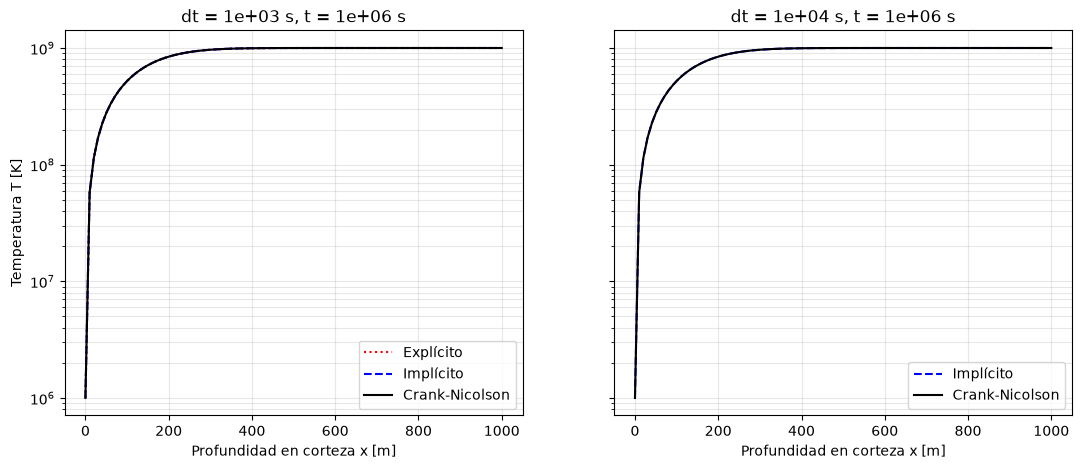

dt = 1e+03 s | Explícito       | max|T - T_CN(dt=1e3)| = 1.372e+05 K
dt = 1e+03 s | Implícito       | max|T - T_CN(dt=1e3)| = 1.373e+05 K
dt = 1e+03 s | Crank-Nicolson  | max|T - T_CN(dt=1e3)| = 0.000e+00 K
dt = 1e+04 s | Explícito       | inestable (se detuvo en el paso 13)
dt = 1e+04 s | Implícito       | max|T - T_CN(dt=1e3)| = 1.373e+06 K
dt = 1e+04 s | Crank-Nicolson  | max|T - T_CN(dt=1e3)| = 4.741e+03 K


In [23]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
estilos = ["r:", "b--", "k-"]

for c in range(2):
    for m in range(3):
        T_c, estable, paso = resultados[(dts[c], metodos[m])]
        if estable:
            ejes[c].plot(x, T_c, estilos[m], label=metodos[m])
    ejes[c].set_title(f"dt = {dts[c]:.0e} s, t = {t_max:.0e} s")
    ejes[c].set_xlabel("Profundidad en corteza x [m]")
    ejes[c].set_yscale("log")
    ejes[c].legend()
    ejes[c].grid(True, which="both", alpha=0.3)

ejes[0].set_ylabel("Temperatura T [K]")
plt.show()

T_ref = resultados[(1.0e3, "Crank-Nicolson")][0]
for dt_c in dts:
    for m in range(3):
        T_c, estable, paso = resultados[(dt_c, metodos[m])]
        if estable:
            dif = np.max(np.abs(T_c - T_ref))
            print(f"dt = {dt_c:.0e} s | {metodos[m]:15s} | max|T - T_CN(dt=1e3)| = {dif:.3e} K")
        else:
            print(f"dt = {dt_c:.0e} s | {metodos[m]:15s} | inestable (se detuvo en el paso {paso})")

## Discusión

**Flujo en la superficie.** En escala log-log, el flujo baja como una recta con pendiente cercana a -1/2 (ajuste: -0.498). Es decir, F ∝ t^(-1/2): el flujo disminuye con el tiempo porque la zona ya enfriada se hace más gruesa y el calor tarda más en llegar a la superficie.

**Estabilidad.**
- Explícito: solo funciona si λ ≤ 1/2. Con Δt = 10³ s (λ = 0.098) funciona; con Δt = 10⁴ s (λ = 0.98) la solución explota en 13 pasos.
- Implícito y Crank-Nicolson: son estables con ambos Δt.

**Precisión.** Con Δt = 10⁴ s, Crank-Nicolson queda mucho más cerca de la solución de referencia que el implícito (diferencia de 4.7×10³ K contra 1.4×10⁶ K). Por eso Crank-Nicolson es el mejor: es estable y además más preciso.

**Neutrinos.** Con T⁵ el término de pérdida es muy pequeño (10⁻⁸ K/s), así que casi todo el enfriamiento viene de la difusión.